<a href="https://colab.research.google.com/github/alla-malts-ds/data-visualization-practice/blob/main/%22HW_11_1_%D0%92%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%B4%D0%B0%D0%BD%D0%B8%D1%85_%D0%B7_Pandas_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Візуалізація даних з Pandas

## Опис завдання
У цьому домашньому завданні ви працюватимете з датасетом про оренду велосипедів `yulu_rental.csv`. Датасет містить інформацію про кількість орендованих велосипедів залежно від погодних умов, сезону та інших факторів.
Набір даних взяти з Kaggle. Посилання на оригінальний [опис](https://www.kaggle.com/datasets/ranitsarkar01/yulu-bike-sharing-data?select=yulu_bike_sharing_dataset.csv).

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів



---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.


Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

## Підготовка даних


In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження даних
df = pd.read_csv('/content/drive/MyDrive/Data_Loves_Academy/Module 11/yulu_rental.csv')

In [3]:
df.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [4]:
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

## Завдання 0: Перегляд даних
**Завдання:**
Перегляньте дані, їх розмір, та напишіть висновок:
- скільки даних в наборі
- який рівень деталізації мають ці дані, тобто за який період міститься дані в одному рядку даних ?

In [5]:
print('Кількість рядків:', df.shape[0])
print('Кількість колонок:', df.shape[1])

print('\nПочаток періоду:', df.index.min())
print('Кінець періоду:', df.index.max())

print('\nПерші п’ять рядків:')
time_interval = df.index.to_series().diff().mode()[0]

print('Період даних в одному рядку:', time_interval)
print('Один рядок містить дані за одну годину.')
display(df.head())

Кількість рядків: 10886
Кількість колонок: 19

Початок періоду: 2011-01-01 00:00:00
Кінець періоду: 2012-12-19 23:00:00

Перші п’ять рядків:
Період даних в одному рядку: 0 days 01:00:00
Один рядок містить дані за одну годину.


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4


## Завдання 1: Базовий лінійний графік

**Завдання:**
1. Згрупуйте дані про кількість орендованих велосипедів (`count`) поденно.
2. Побудуйте з методом `DataFrame.plot()` лінійний графік поденної кількості орендованих велосипедів (`count`) за весь період в даних.
3. Налаштуйте розмір графіка (12x6), додайте заголовок "Динаміка оренди велосипедів" та сітку.
4. Дайте відповіді на питання по цьому графіку. Якщо треба - проведіть додаткові програмні операції для відповідей.

**Питання для інтерпретації:**
1. Як гадаєте, чому графік має "заломи", чим це спричинено і як ви б могли прибрати заломи?
2. Які загальні тенденції ви бачите на графіку?
3. Чи помітні якісь сезонні коливання?
4. Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?


<Axes: title={'center': 'Динаміка оренди велосипедів'}, xlabel='Дата', ylabel='Кількість оренд'>

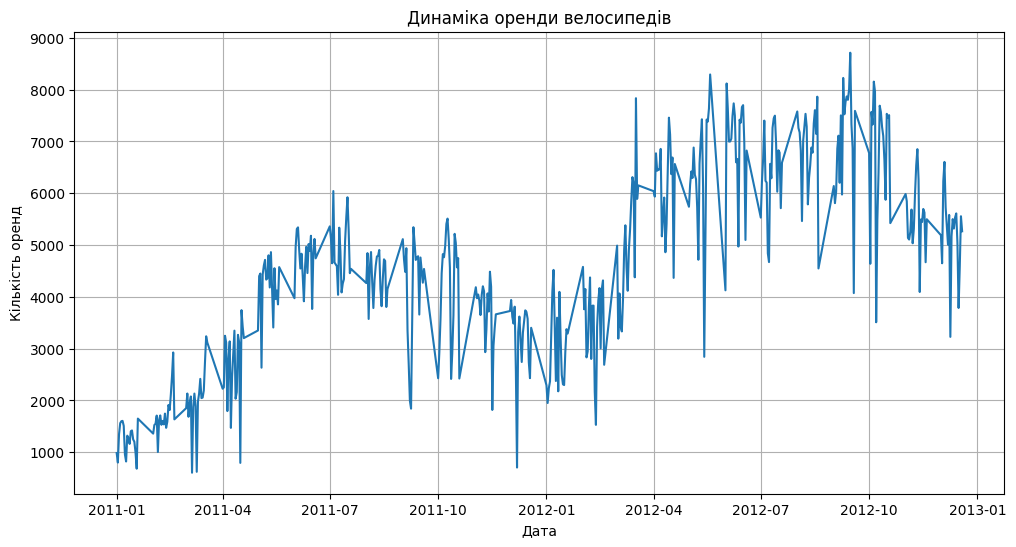

In [6]:
df.groupby('date')['count'].sum().plot(figsize=(12,6), title='Динаміка оренди велосипедів', grid=True, xlabel='Дата',ylabel='Кількість оренд')


Лінійний графік показує загальну тенденцію до зростання кількості оренд велосипедів протягом досліджуваного періоду. У 2011 році кількість оренд поступово збільшилася приблизно з 1 000–1 500 до 4 000–5 000 оренд на день. У 2012 році попит став ще вищим: у періоди найбільшої активності показник перевищував 8 000 оренд на день, а максимальне значення становило приблизно 8 700.

На графіку помітні сезонні коливання. Кількість оренд переважно зростає навесні та влітку, коли погодні умови сприятливіші для поїздок на велосипеді, і зменшується восени та взимку.

Різкі «заломи» можуть бути пов’язані не лише зі зміною попиту, а й зі структурою набору даних. У датасеті представлені лише дні з 1-го до 19-го числа кожного місяця, тому між останнім доступним днем одного місяця та першим днем наступного є пропуски. Лінійний графік автоматично з’єднує такі віддалені дати прямими лініями, через що виникають різкі переходи. Щоб коректніше показати часові розриви, можна створити повний календар дат і залишити пропущені дні як порожні значення.

Окремі аномально низькі значення можуть пояснюватися несприятливими погодними умовами, низькою температурою, високою вологістю, сильним дощем або святковими днями. Високі значення можуть бути пов’язані зі сприятливою погодою, робочими днями та загальним зростанням популярності сервісу. Для перевірки цих припущень потрібно додатково порівняти count із колонками weather, temp, humidity, windspeed, workingday і holiday.


## Завдання 2: Аналіз сезонності (Bar Plot)

**Завдання:**
Побудуйте вертикальну стовпчасту діаграму середньої кількості орендованих велосипедів за сезонами(кварталами). Додайте підписи осей і заголовок.

Просунуте доповнення:
1. Позначте квартали не числом, а назвою на візуалізації.
2. Додайте підписи над стовпцями зі значеннями в кожному стовпці.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В який квартал найбільша середня кількість оренди велосипедів?
2. Як ви можете пояснити таку сезонну закономірність?
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?

Найбільша середня кількість оренд у кварталі: Q3
Найменша середня кількість оренд у кварталі: Q1
Оренда відрізняється у 2.01 раза.


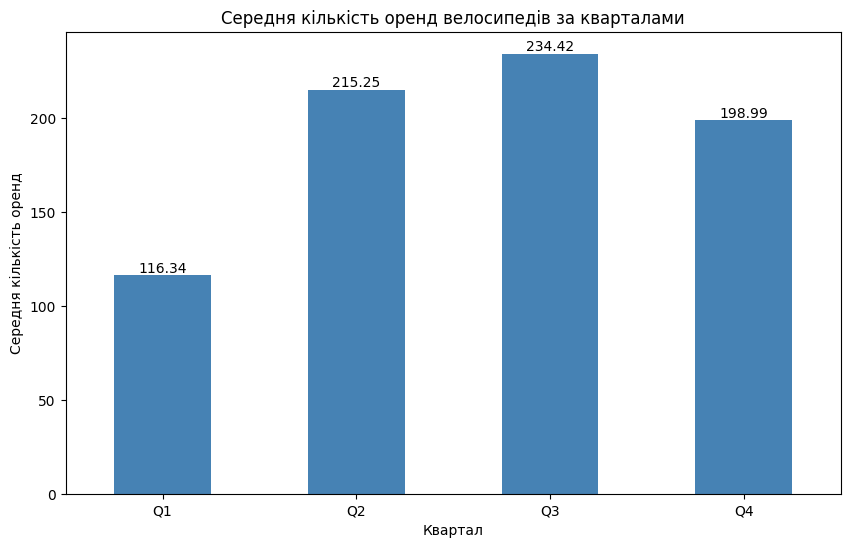

In [7]:
seasonal_avg = df.groupby('season')['count'].mean().rename(index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4'}).round(2)

ax = seasonal_avg.plot(
    kind='bar',
    figsize=(10, 6),
    title='Середня кількість оренд велосипедів за кварталами',
    xlabel='Квартал',
    ylabel='Середня кількість оренд',
    color='steelblue',
    rot=0
)

ax.bar_label(ax.containers[0], fmt='%.2f')

top_quarter = seasonal_avg.idxmax()
lowest_quarter = seasonal_avg.idxmin()
difference = seasonal_avg.max() / seasonal_avg.min()

print(f'Найбільша середня кількість оренд у кварталі: {top_quarter}')
print(f'Найменша середня кількість оренд у кварталі: {lowest_quarter}')
print(f'Оренда відрізняється у {difference:.2f} раза.')

Пояснення: така сезонна закономірність передусім може бути пов’язана зі зміною погодних умов протягом року. У тепліші квартали температура комфортніша для поїздок, довший світловий день і менша ймовірність несприятливої погоди, тому велосипеди орендують частіше. У холодніші квартали низька температура, опади, висока вологість і сильний вітер можуть знижувати попит. Крім того, на результат може впливати загальне зростання популярності сервісу у 2012 році, тому для точнішого висновку варто додатково проаналізувати показники temp, weather, humidity, windspeed і year.

## Завдання 3: Динаміка за місяцями (Line Plot)

**Завдання:**
Створіть лінійний графік середньої кількості оренд велосипедів на годину по місяцях (тобто групування в рамках місяця і беремо середню кількість оренд у цей місяць з кількох років). Використайте маркери-кружечки для точок, додайте сітку та пофарбуйте лінію у червоний колір.

Просунуте доповнення:
- додайте аби по осі ОХ поділки були чітко на кожен окремий місяць по одній. Тобто сумарно 12 поділок.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які місяці спостерігається пік та спад оренди?
2. Чи збігається ця закономірність з результатами з попереднього завдання?
3. Як може вплинути клімат на оренду велосипедів протягом року?


Пік оренди спостерігається у червні: 242.03 оренд за годину.
Найнижчий показник спостерігається у січні: 90.37 оренд за годину.


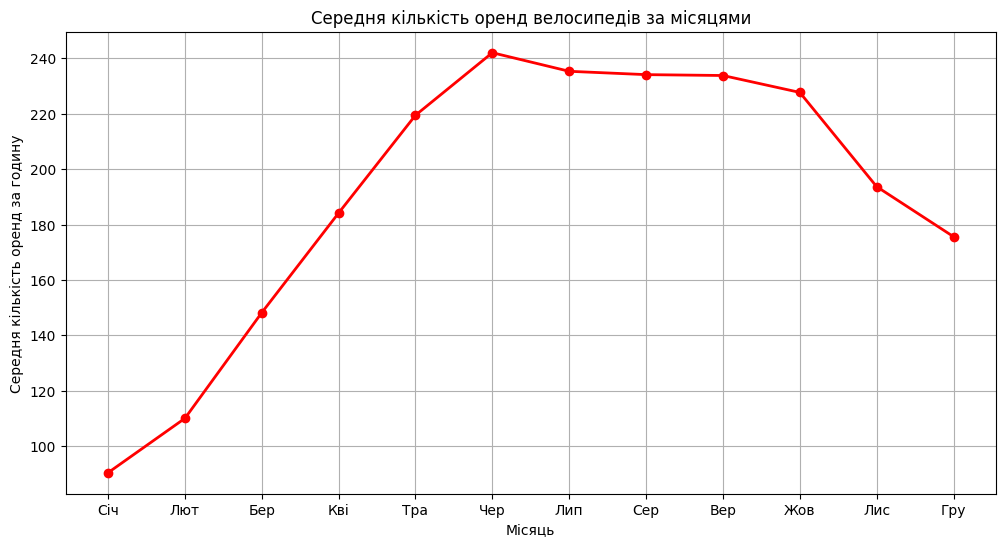

In [8]:
monthly_avg = df.groupby('month')['count'].mean()

ax = monthly_avg.plot(
    kind='line',
    figsize=(12, 6),
    color='red',
    marker='o',
    linewidth=2,
    title='Середня кількість оренд велосипедів за місяцями',
    xlabel='Місяць',
    ylabel='Середня кількість оренд за годину',
    grid=True,
    xticks=range(1, 13)
)

ax.set_xticklabels([
    'Січ', 'Лют', 'Бер', 'Кві', 'Тра', 'Чер',
    'Лип', 'Сер', 'Вер', 'Жов', 'Лис', 'Гру'
])

peak_month = monthly_avg.idxmax()
lowest_month = monthly_avg.idxmin()

month_names = {
    1: 'січні', 2: 'лютому', 3: 'березні', 4: 'квітні',
    5: 'травні', 6: 'червні', 7: 'липні', 8: 'серпні',
    9: 'вересні', 10: 'жовтні', 11: 'листопаді', 12: 'грудні'
}
print(
    f'Пік оренди спостерігається у {month_names[peak_month]}: '
    f'{monthly_avg.max():.2f} оренд за годину.'
)

print(
    f'Найнижчий показник спостерігається у {month_names[lowest_month]}: '
    f'{monthly_avg.min():.2f} оренд за годину.'
)

Порівняння з попереднім завданням

Так, закономірність загалом збігається з попереднім аналізом за кварталами. Найвища активність припадає на теплішу частину року, особливо на кінець другого та третій квартали. Найнижчий попит спостерігається у першому кварталі, до якого входять холодні січень, лютий і березень.

Вплив клімату

Клімат може суттєво впливати на оренду велосипедів. У теплі місяці комфортніша температура та довший світловий день роблять велосипед зручнішим для щоденних і рекреаційних поїздок. Узимку низька температура, коротший світловий день, опади та сильний вітер можуть зменшувати попит. Незначне зниження після червня може бути пов’язане з надмірною літньою спекою, вологістю або сезоном опадів, тому найвища температура не обов’язково означає найбільшу кількість оренд.

## Завдання 4: Розподіл погодних умов (Pie Chart)

**Завдання:**
1. Побудуйте кругову діаграму з часткою записів за погодними умовами
2. Додайте підписи з відсотками та легенду з описами погоди (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ).
3. Визначте свої відмінні від стандартних кольори для відображення кожної категорії.
4. Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. Яка погода переважає в датасеті?
2. Чи є дні із сильним дощем? Яка їх частка?
3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?

Очікуваний результат:

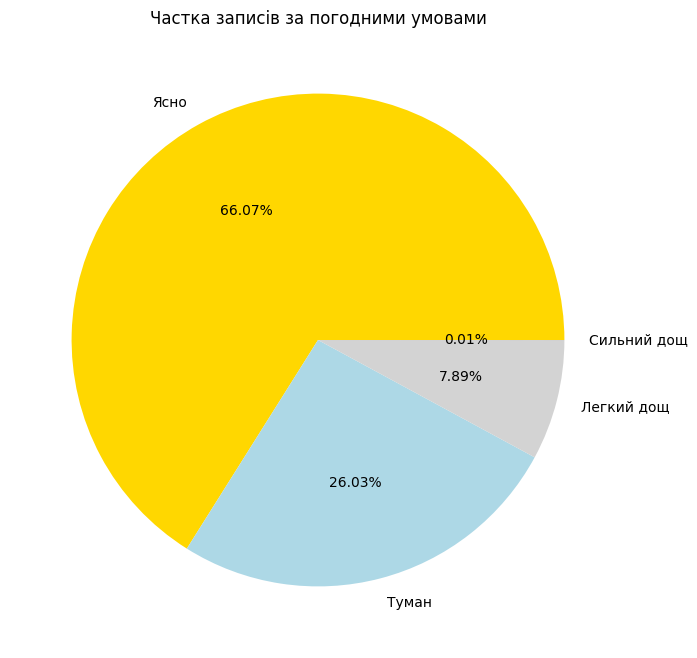

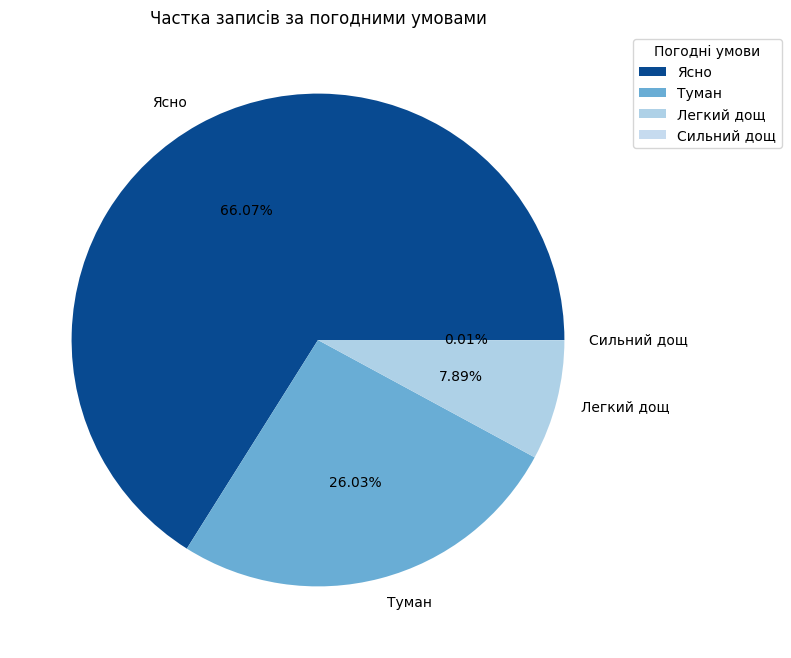

In [15]:
weather_share = df['weather'].value_counts().sort_index().rename(
    index={
        1: 'Ясно',
        2: 'Туман',
        3: 'Легкий дощ',
        4: 'Сильний дощ'
    }
)
normalized_values = (
    (weather_share - weather_share.min()) /
    (weather_share.max() - weather_share.min())
)
colors = plt.cm.Blues(0.25 + 0.65 * normalized_values)

weather_share.plot(
    kind='pie',
    figsize=(8, 8),
    autopct='%.2f%%',
    startangle=0,
    colors=colors,
    title='Частка записів за погодними умовами',
    ylabel=''
)

plt.legend(
    title='Погодні умови',
    loc='upper left',
    bbox_to_anchor=(1, 1)
)

plt.show()

Висновок: у датасеті переважає ясна погода, на яку припадає 66,07% усіх записів. Туман спостерігається у 26,03%, легкий дощ у 7,89%, а сильний дощ лише у 0,01% записів.

Погодні умови можуть суттєво впливати на попит на оренду велосипедів. За ясної погоди поїздки є комфортнішими, тому кількість оренд може зростати. Туман може зменшувати попит через погіршення видимості, а дощ робить поїздки менш комфортними та безпечними. Найбільше зниження попиту можна очікувати під час сильного дощу.

Водночас ця кругова діаграма показує лише частоту погодних умов у датасеті, а не їхній фактичний вплив на кількість оренд. Щоб перевірити вплив погоди, потрібно окремо порівняти середнє значення count для кожної категорії weather.

## Завдання 5: Box Plot для аналізу викидів

**Завдання:**
Створіть коробковий графік (box plot) кількості орендованих велосипедів для кожного типу погоди.

Просунуте доповнення:
- Використайте горизонтальну орієнтацію.
- Позначте погодні умови не числом, а назвою на візуалізації.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. При якій погоді найбільший розкид у кількості оренди?
2. Чи є викиди (outliers) в даних? При якій погоді?
3. При якій погоді медіанне значення оренди найвище?

/tmp/ipykernel_1387/1107485010.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(


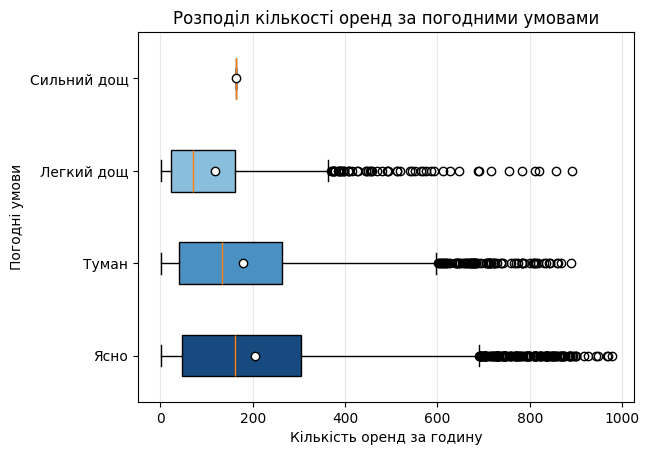

In [16]:
weather_names = {
    1: 'Ясно',
    2: 'Туман',
    3: 'Легкий дощ',
    4: 'Сильний дощ'
}

df['weather_name'] = df['weather'].map(weather_names)

weather_order = [
    'Ясно',
    'Туман',
    'Легкий дощ',
    'Сильний дощ'
]

weather_data = [
    df.loc[df['weather_name'] == weather, 'count']
    for weather in weather_order
]

box = plt.boxplot(
    weather_data,
    vert=False,
    labels=weather_order,
    patch_artist=True,
    showmeans=True,
    meanprops={
        'marker': 'o',
        'markerfacecolor': 'white',
        'markeredgecolor': 'black'
    }
)

colors = [
    '#174A7E',
    '#4A90C2',
    '#89BEDC',
    '#D5EAF4'
]

for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

plt.figure
plt.title('Розподіл кількості оренд за погодними умовами')
plt.xlabel('Кількість оренд за годину')
plt.ylabel('Погодні умови')
plt.grid(axis='x', alpha=0.3)
plt.show()

1.Найбільший розкид у кількості оренд спостерігається за ясної погоди. Коробка для категорії «Ясно» є найдовшою, тобто центральні 50% погодинних значень оренди мають найбільший діапазон.

2.Так, у даних є викиди. Вони позначені чорними кружечками за межами «вусів» графіка та спостерігаються за ясної погоди, туману й легкого дощу. Найбільш високі значення за ясної погоди наближаються до 1 000 оренд за годину. Такі значення не обов’язково є помилками, адже можуть відповідати ранковим або вечірнім годинам пік.

3.Серед погодних категорій із достатньою кількістю спостережень найвище медіанне значення має ясна погода. Категорію «Сильний дощ» не варто використовувати для надійного порівняння: вона містить надто мало спостережень, тому повноцінна коробка для неї фактично не сформувалася.

## Завдання 6: Кореляція температури та оренди (Scatter Plot)

**Завдання:**
Побудуйте діаграму розсіювання залежності між температурою (`temp`) та загальною кількістю оренди (`count`). Розфарбуйте точки за сезонами, додайте напівпрозорість (alpha=0.6).

**Увага!** За замовченням буде колір

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
- Чи є зв'язок між температурою та кількістю оренди? Який?

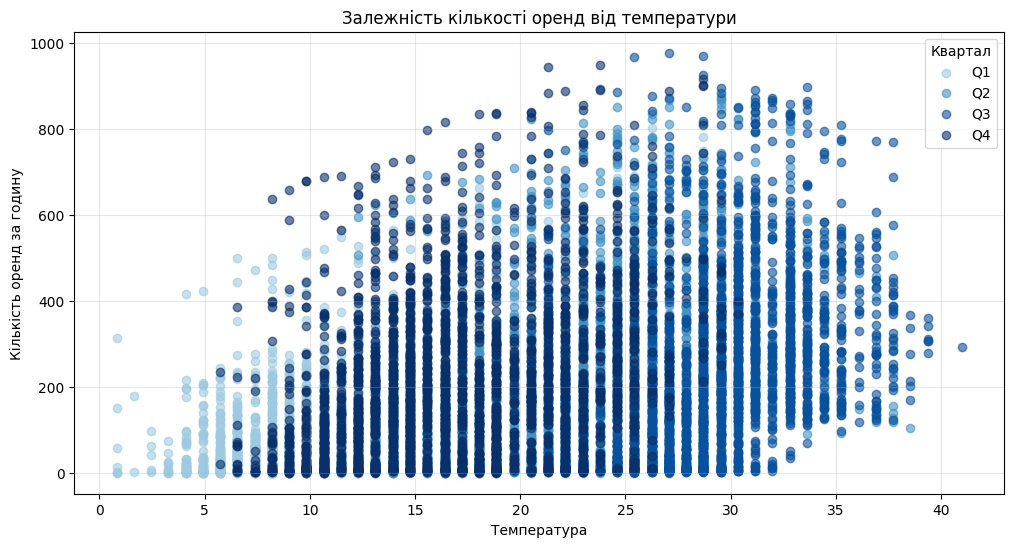

In [17]:
season_names = {
    1: 'Q1',
    2: 'Q2',
    3: 'Q3',
    4: 'Q4'
}

colors = {
    1: '#9ECAE1',
    2: '#4292C6',
    3: '#08519C',
    4: '#08306B'
}

plt.figure(figsize=(12, 6))

for season in sorted(df['season'].unique()):
    season_data = df[df['season'] == season]

    plt.scatter(
        season_data['temp'],
        season_data['count'],
        label=season_names[season],
        color=colors[season],
        alpha=0.6
    )

plt.title('Залежність кількості оренд від температури')
plt.xlabel('Температура')
plt.ylabel('Кількість оренд за годину')
plt.legend(title='Квартал')
plt.grid(alpha=0.3)
plt.show()

Між температурою та кількістю оренд спостерігається позитивний зв’язок: зі зростанням температури частіше зустрічаються години з великою кількістю оренд.

На графіку видно:

-за температури приблизно 0–10 °C більшість значень оренди невисокі
-у діапазоні близько 15–30 °C значно частіше зустрічається 400–800 оренд за годину
-найбільші значення, близько 900–980 оренд, переважно спостерігаються за температури приблизно 20–30 °C
-після приблизно 30–35 °C подальшого очевидного зростання попиту вже не видно.

Водночас точки сильно розсіяні по вертикалі. За однакової температури кількість оренд може бути як дуже низькою, так і високою. Отже, температура впливає на попит, але не пояснює його повністю.
На кількість оренд також можуть впливати:

-година доби
-робочий або вихідний день
-квартал і місяць
-дощ або туман
-вологість і вітер
-рік спостереження

Кольори кварталів суттєво перекриваються. Це означає, що температура та квартал пов’язані між собою, але всередині кожного кварталу все одно залишається великий розкид оренди.

#Перевіримо звязок програмно

In [18]:
correlation = df['temp'].corr(df['count'])

print(
    f'Коефіцієнт кореляції між температурою '
    f'та кількістю оренд: {correlation:.2f}'
)

Коефіцієнт кореляції між температурою та кількістю оренд: 0.39


Висновок: коефіцієнт кореляції між температурою та кількістю оренд становить 0,39, що свідчить про помірний позитивний зв’язок. Зі зростанням температури кількість оренд велосипедів загалом має тенденцію збільшуватися

## (Опціонально) Завдання 7: Порівняння користувачів (Stacked Bar Chart)

**Завдання:**
Ми хочемо дізнатись як по дням тижня беруть в середньому в оренду велосипеди випадкові і зареєстровані користувачі.

Створіть стовпчасту діаграму з накопиченням (bar з налаштуванням `stacked=True`), яка показує співвідношення випадкових (`casual`) та зареєстрованих (`registered`) користувачів по днях тижня за кількістю взятих ними велосипедів в оренду в середньому. Використайте різні кольори для типів користувачів.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які дні тижня більше оренд від зареєстрованих користувачів?
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?

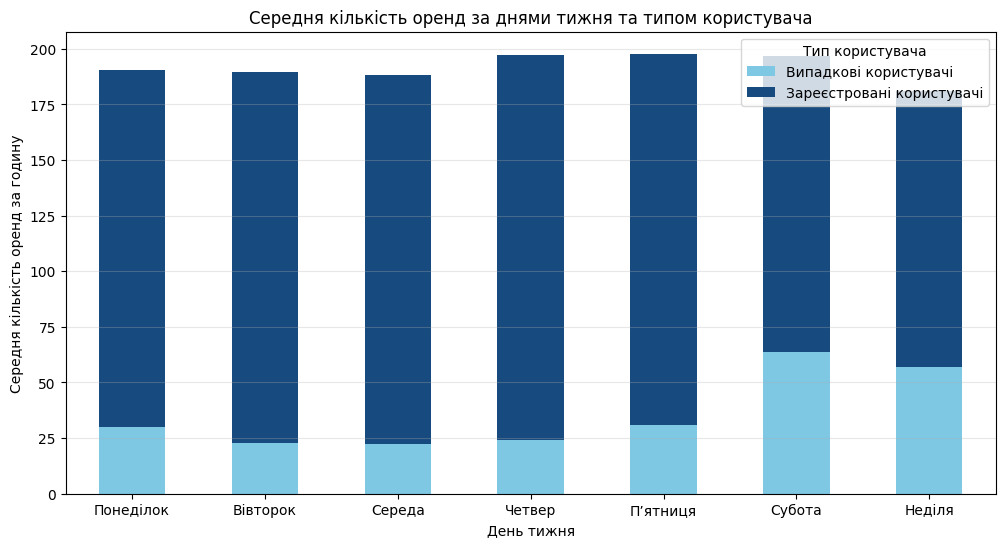

In [19]:
weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekday_names = {
    'Monday': 'Понеділок',
    'Tuesday': 'Вівторок',
    'Wednesday': 'Середа',
    'Thursday': 'Четвер',
    'Friday': 'П’ятниця',
    'Saturday': 'Субота',
    'Sunday': 'Неділя'
}

users_by_weekday = (
    df.groupby('weekday')[['casual', 'registered']]
      .mean()
      .reindex(weekday_order)
      .rename(index=weekday_names)
)

ax = users_by_weekday.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=['#7EC8E3', '#174A7E'],
    title='Середня кількість оренд за днями тижня та типом користувача',
    xlabel='День тижня',
    ylabel='Середня кількість оренд за годину',
    rot=0
)

plt.legend(
    ['Випадкові користувачі', 'Зареєстровані користувачі'],
    title='Тип користувача'
)

plt.grid(axis='y', alpha=0.3)
plt.show()

Висновок: зареєстровані користувачі переважають у структурі оренд протягом усього тижня. Найвища їхня активність спостерігається у робочі дні, особливо в четвер і п’ятницю, а у вихідні середня кількість оренд зменшується. Це може пояснюватися тим, що зареєстровані користувачі регулярно використовують велосипеди для поїздок на роботу або навчання. Водночас активність випадкових користувачів різко зростає у суботу та неділю, що може бути пов’язано з прогулянками, відпочинком і туристичними поїздками. Отже, у будні попит переважно має регулярний транспортний характер, а у вихідні посилюється рекреаційне використання велосипедів.